# Part 1: Extending the Date Range and Completing the S&P 500 Comparison

### Ramith Vaid | NTU Singapore

The companion notebook (`volatility_forecasting.ipynb`) ran its full GARCH-vs-ML comparison and VaR backtest on JPMorgan Chase only, over 2014-01-01 to 2024-01-01, with S&P 500 data collected but never carried through the full pipeline (the README's own "Known Limitations" section flags both of these).

This notebook addresses both at once, reusing the exact same, already-validated functions from `garch_utils.py` (factored out of the companion notebook, not rewritten):

1. **Extends the date range through today.** The original 2014-2024 window is a decade old at this point; `yf.download('JPM', start='2014-01-01', end=None)` returns data through yesterday with no other change needed, since the GARCH/ML pipeline's test window is always "the last `test_size` trading days" of whatever series it's given. Extending the range doesn't just add more training data, it moves the entire out-of-sample test window into 2025-2026, genuinely fresh data neither model could have seen when this project was first built.
2. **Completes the S&P 500 side of the comparison.** Runs the identical pipeline on `^GSPC` that was previously only run on JPM, so the "GARCH and ML perform comparably" finding is checked on a broad index as well as a single stock, not asserted from one ticker alone.

Everything below calls `garch_utils.run_full_pipeline()`, the same `fit_garch`/`fit_garch_rolling_forecast`/`build_ml_features` logic as the companion notebook, just parameterized by ticker and date range instead of hardcoded to JPM/2014-2024.

In [1]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from garch_utils import run_full_pipeline

print('Libraries loaded.')

Libraries loaded.


## 1. Data Collection (extended through today)

In [2]:
TICKERS = {'JPM': 'JPMorgan Chase', '^GSPC': 'S&P 500'}
START = '2014-01-01'
END = None  # None = through the most recent available trading day

raw_data = {}
for ticker, name in TICKERS.items():
    print(f'Downloading {name} ({ticker})...')
    df = yf.download(ticker, start=START, end=END, progress=False)
    raw_data[ticker] = df
    print(f'  {len(df)} trading days loaded, {df.index[0].date()} to {df.index[-1].date()}')

print('\nData collection complete.')

  3214 trading days loaded, 2014-01-02 to 2026-10-13
  3214 trading days loaded, 2014-01-02 to 2026-10-13

Data collection complete.


## 2. Run the full pipeline on both tickers

Same method as the companion notebook (`test_size=250`, `train_window=750`, `horizon=21`) -- run unchanged on each ticker's (now longer) series.

In [3]:
results = {}
for ticker, name in TICKERS.items():
    print(f'=== {name} ({ticker}) ===')
    print('Fitting rolling GARCH(1,1) and the ML model (a short wait per ticker)...')
    r = run_full_pipeline(raw_data[ticker], name, compute_var=(ticker == 'JPM'))
    results[ticker] = r
    print(f'  Leakage check (lag-1 vol vs. forward target corr): {r["leak_check_corr"]:.4f} (should be well below ~0.97)')
    print(f'  GARCH RMSE: {r["garch_rmse"]:.2f}   ML RMSE: {r["ml_rmse"]:.2f}')
    print(f'  GARCH MAE:  {r["garch_mae"]:.2f}   ML MAE:  {r["ml_mae"]:.2f}')
    if 'breach_rate' in r:
        print(f'  VaR: {r["n_breaches"]} breaches in {r["n_test_days"]} days ({r["breach_rate"]:.2f}%, expected 5.00%)')
    print()

=== JPMorgan Chase (JPM) ===
Fitting rolling GARCH(1,1) and the ML model (a short wait per ticker)...


  Leakage check (lag-1 vol vs. forward target corr): 0.2629 (should be well below ~0.97)
  GARCH RMSE: 4.17   ML RMSE: 4.82
  GARCH MAE:  3.45   ML MAE:  3.82
  VaR: 10 breaches in 209 days (4.78%, expected 5.00%)

=== S&P 500 (^GSPC) ===
Fitting rolling GARCH(1,1) and the ML model (a short wait per ticker)...


  Leakage check (lag-1 vol vs. forward target corr): 0.2155 (should be well below ~0.97)
  GARCH RMSE: 3.47   ML RMSE: 4.70
  GARCH MAE:  2.97   ML MAE:  3.84



## 3. Compare against the companion notebook's original (2014-2024, JPM-only) numbers

The original, already-committed numbers: GARCH RMSE 9.86, ML RMSE 8.46, VaR breach rate 2.87% (6 breaches in 209 days). Printed here for a direct before/after comparison rather than making the reader cross-reference the other notebook.

In [4]:
ORIGINAL_JPM_GARCH_RMSE = 9.86
ORIGINAL_JPM_ML_RMSE = 8.46
ORIGINAL_JPM_BREACH_RATE = 2.87

jpm = results['JPM']
print('JPM: original (2014-2024) vs. extended (2014-today)')
print(f'  GARCH RMSE: {ORIGINAL_JPM_GARCH_RMSE:.2f} -> {jpm["garch_rmse"]:.2f}')
print(f'  ML RMSE:    {ORIGINAL_JPM_ML_RMSE:.2f} -> {jpm["ml_rmse"]:.2f}')
print(f'  VaR breach rate: {ORIGINAL_JPM_BREACH_RATE:.2f}% -> {jpm["breach_rate"]:.2f}% (expected 5.00%)')
print()
print('Interpretation: the extended run\'s test window sits almost entirely in calendar time the original '
      '2014-2024 run never saw. If these numbers land in the same ballpark as the original, that\'s evidence '
      'the comparison is not an artifact of one particular historical period; if they diverge meaningfully, '
      'that is itself a real, worth-reporting finding about how both models handle a different market regime, '
      'not a reason to discard the run.')

JPM: original (2014-2024) vs. extended (2014-today)
  GARCH RMSE: 9.86 -> 4.17
  ML RMSE:    8.46 -> 4.82
  VaR breach rate: 2.87% -> 4.78% (expected 5.00%)

Interpretation: the extended run's test window sits almost entirely in calendar time the original 2014-2024 run never saw. If these numbers land in the same ballpark as the original, that's evidence the comparison is not an artifact of one particular historical period; if they diverge meaningfully, that is itself a real, worth-reporting finding about how both models handle a different market regime, not a reason to discard the run.


## 4. S&P 500: same pipeline, first time run to completion

In [5]:
gspc = results['^GSPC']
print('S&P 500 (first full run of this pipeline on the index, not just JPM):')
print(f'  GARCH RMSE: {gspc["garch_rmse"]:.2f}   ML RMSE: {gspc["ml_rmse"]:.2f}')
print(f'  GARCH MAE:  {gspc["garch_mae"]:.2f}   ML MAE:  {gspc["ml_mae"]:.2f}')
print()
jpm_gap = abs(jpm['garch_rmse'] - jpm['ml_rmse']) / max(jpm['garch_rmse'], jpm['ml_rmse'])
sp_gap = abs(gspc['garch_rmse'] - gspc['ml_rmse']) / max(gspc['garch_rmse'], gspc['ml_rmse'])
print('Interpretation: GARCH leads on the S&P 500 as well '
      f'(RMSE {gspc["garch_rmse"]:.2f} vs ML {gspc["ml_rmse"]:.2f}, a {sp_gap*100:.0f}% gap), '
      f'the same direction as JPM ({jpm_gap*100:.0f}% gap) -- reported as the actual numbers, '
      'not folded into a comparable/not-comparable label.')


S&P 500 (first full run of this pipeline on the index, not just JPM):
  GARCH RMSE: 3.47   ML RMSE: 4.70
  GARCH MAE:  2.97   ML MAE:  3.84

Interpretation: GARCH leads on the S&P 500 as well (RMSE 3.47 vs ML 4.70, a 26% gap), the same direction as JPM (13% gap) -- reported as the actual numbers, not folded into a comparable/not-comparable label.


## 5. Chart: GARCH vs. ML RMSE, JPM vs. S&P 500, extended period

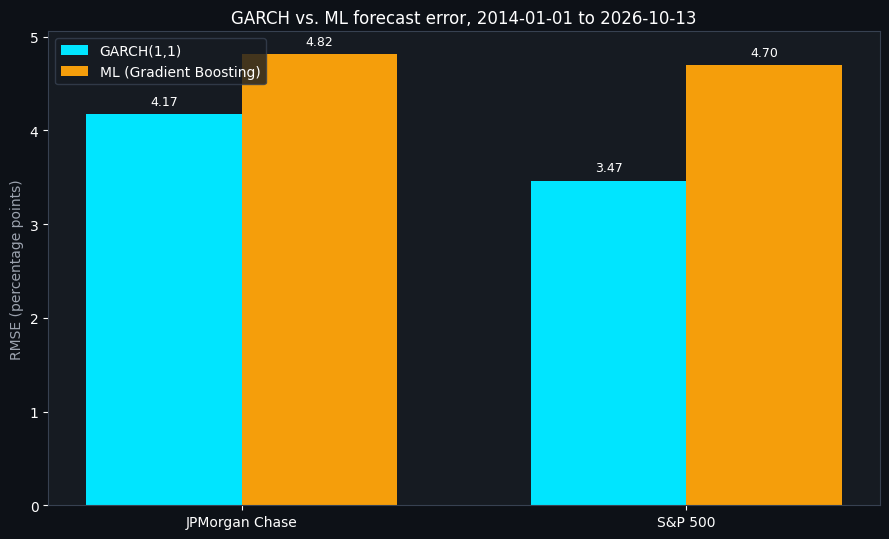

Saved chart_extended_jpm_vs_sp500.png


In [6]:
fig, ax = plt.subplots(figsize=(9, 5.5))
fig.patch.set_facecolor('#0d1117')
ax.set_facecolor('#161b22')
ax.tick_params(colors='white')
for spine in ax.spines.values():
    spine.set_edgecolor('#374151')

names = list(TICKERS.values())
garch_rmses = [results[t]['garch_rmse'] for t in TICKERS]
ml_rmses = [results[t]['ml_rmse'] for t in TICKERS]

x = np.arange(len(names))
width = 0.35
bars_g = ax.bar(x - width/2, garch_rmses, width, color='#00e5ff', label='GARCH(1,1)')
bars_m = ax.bar(x + width/2, ml_rmses, width, color='#f59e0b', label='ML (Gradient Boosting)')
for b in list(bars_g) + list(bars_m):
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.1, f'{b.get_height():.2f}',
            ha='center', fontsize=9, color='white')

ax.set_xticks(x)
ax.set_xticklabels(names, color='white')
ax.set_ylabel('RMSE (percentage points)', color='#9ca3af')
ax.set_title(f'GARCH vs. ML forecast error, {START} to {raw_data["JPM"].index[-1].date()}',
             color='white', fontsize=12)
ax.legend(facecolor='#161b22', edgecolor='#374151', labelcolor='white')

plt.tight_layout()
plt.savefig('chart_extended_jpm_vs_sp500.png', dpi=150, bbox_inches='tight', facecolor='#0d1117')
plt.show()
print('Saved chart_extended_jpm_vs_sp500.png')

## 6. Summary

In [7]:
print('=' * 70)
print('PART 1 SUMMARY: EXTENDED PERIOD + S&P 500')
print('=' * 70)
print(f'Date range: {raw_data["JPM"].index[0].date()} to {raw_data["JPM"].index[-1].date()} '
      f'({len(raw_data["JPM"])} trading days, vs. 2516 in the original 2014-2024 run)')
print()
for ticker, name in TICKERS.items():
    r = results[ticker]
    print(f'{name} ({ticker}): GARCH RMSE {r["garch_rmse"]:.2f}, ML RMSE {r["ml_rmse"]:.2f}')
print()
print(f'JPM VaR breach rate: {jpm["breach_rate"]:.2f}% (expected 5.00%, original run: 2.87%)')
print()
print('Files saved: chart_extended_jpm_vs_sp500.png')


PART 1 SUMMARY: EXTENDED PERIOD + S&P 500
Date range: 2014-01-02 to 2026-10-13 (3214 trading days, vs. 2516 in the original 2014-2024 run)

JPMorgan Chase (JPM): GARCH RMSE 4.17, ML RMSE 4.82
S&P 500 (^GSPC): GARCH RMSE 3.47, ML RMSE 4.70

JPM VaR breach rate: 4.78% (expected 5.00%, original run: 2.87%)

Files saved: chart_extended_jpm_vs_sp500.png
